# P4: Trust check and triage (G03 Brain MRI Triage)

**Pipeline:** slice → mask (ground truth or P2 U-Net) → crop (P2) → ResNet-50 (P3) → class + confidence → Grad-CAM → IoU(heatmap, mask) → triage tier.

**Triage rule** (IoU thresholds tuned on dev; proposal values in brackets):
- **High Priority**: glioma or meningioma, confidence > 0.80, IoU > 0.20 [0.50]
- **Needs Review**: confidence < 0.60 or IoU < 0.02 [0.30]
- **Routine**: everything else
- Added: if the prediction is *notumor*, there is no tumor region, so IoU is undefined → confidence test only.

**Fair test:** all tuning on dev. Test is run once, at the end (`RUN_TEST`).

## 1. Settings
Model files are not in git. Put `p3_crop_best.pt` (Mihir) and `best_unet.pth` (Anika) in `MODELS_DIR`.

In [1]:
import os, sys

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_ROOT = '/content/drive/MyDrive/integration_project'
    REPO_ROOT = '/content/G03-brain-mri'
    MODELS_DIR = '/content/drive/MyDrive/G03-P3-models'
else:
    DATA_ROOT = os.environ.get('DATA_ROOT', r'C:/Users/DELL/Downloads/integration_project/integration_project')
    REPO_ROOT = os.environ.get('REPO_ROOT', r'C:/Users/DELL/Downloads/G03-brain-mri-main/G03-brain-mri-main')
    MODELS_DIR = os.environ.get('MODELS_DIR', r'C:/Users/DELL/Downloads/G03-P3-models/G03-P3-models')

CLASSIFIER_CKPT = os.environ.get('CLASSIFIER_CKPT', os.path.join(MODELS_DIR, 'p3_crop_best.pt'))  # Mihir (P3)
UNET_CKPT       = os.environ.get('UNET_CKPT', os.path.join(MODELS_DIR, 'best_unet.pth'))           # Anika (P2)
MASK_SOURCE = os.environ.get('MASK_SOURCE', 'unet')  # 'unet' (real pipeline) or 'gt' (true masks, upper bound)
INPUT_MODE  = 'crop'                                 # 'crop' (proposal) or 'full' (baseline model)
DEV_LIMIT   = None                                   # e.g. 50 for a quick run
RUN_TEST    = False                                  # True only for the final report
OUT_DIR = os.path.join(REPO_ROOT, 'P4', 'results')
os.makedirs(OUT_DIR, exist_ok=True)

sys.path.insert(0, os.path.join(REPO_ROOT, 'P4'))
import trust_triage as tt
tt.setup_paths(DATA_ROOT, REPO_ROOT)
print('mask source:', MASK_SOURCE, '| input:', INPUT_MODE, '| device:', tt.pick_device())

mask source: unet | input: crop | device: cpu


## 2. Build the pipeline

In [2]:
import torch, numpy as np, pandas as pd
import matplotlib.pyplot as plt

ckpt = CLASSIFIER_CKPT if os.path.exists(CLASSIFIER_CKPT) else None
if ckpt is None:
    print('WARNING: classifier checkpoint not found -> untrained model, results are meaningless (code test only)')
pipe = tt.TriagePipeline(ckpt, mask_source=MASK_SOURCE, unet_ckpt=UNET_CKPT, input_mode=INPUT_MODE)

## 3. Run on the dev split

In [3]:
dev = pipe.run_split('dev', DATA_ROOT, limit=DEV_LIMIT)
dev.to_csv(os.path.join(OUT_DIR, f'dev_results_{MASK_SOURCE}.csv'), index=False)
tiers, by_class, iou, key = tt.summarize(dev)
print('Tier distribution'); display(tiers)
print('Tier by true class'); display(by_class)
print('Heatmap-mask IoU by true class'); display(iou)
cm = tt.confusion(dev)
print('Confusion matrix (rows true, cols predicted)'); display(cm)
tiers.to_csv(os.path.join(OUT_DIR, f'dev_tiers_{MASK_SOURCE}.csv'))
by_class.to_csv(os.path.join(OUT_DIR, f'dev_tiers_by_class_{MASK_SOURCE}.csv'))
cm.to_csv(os.path.join(OUT_DIR, f'dev_confusion_{MASK_SOURCE}.csv'))
pd.Series(key)

Tier distribution


,count,fraction
tier,,
High Priority,127,0.174
Needs Review,108,0.148
Routine,496,0.679


Tier by true class


tier,High Priority,Needs Review,Routine
true,,,
glioma,79,55,91
meningioma,48,16,49
pituitary,0,36,112
notumor,0,1,244


Heatmap-mask IoU by true class


iou        iou_vs_gt       
             mean median      mean median
true                                     
glioma      0.165  0.158     0.150  0.141
meningioma  0.190  0.174     0.186  0.173
notumor     0.000  0.000     0.000  0.000
pituitary   0.114  0.096     0.110  0.095

Confusion matrix (rows true, cols predicted)


pred,glioma,meningioma,pituitary,notumor
true,,,,
glioma,209,3,8,5
meningioma,4,101,4,4
pituitary,2,0,142,4
notumor,0,1,0,244


n                                            731.000
accuracy                                       0.952
urgent cases moved to High Priority            0.376
High Priority cases that are truly urgent      1.000
errors caught by Needs Review                  0.514
confident errors (conf > 0.8)                 19.000
dtype: float64

## 3b. Threshold tuning (dev only)
Each row: one (LO_IOU, HI_IOU) pair. We want few reviews, many errors caught, and no wrong prediction in High Priority.
Chosen: **LO_IOU = 0.02** (error catch is flat from 0.02 to 0.08, so this gives it with the fewest reviews) and
**HI_IOU = 0.20** (lowest value with no wrong prediction in High Priority). Proposal values: 0.30 / 0.50.

In [4]:
grid = tt.threshold_grid(dev)
grid.to_csv(os.path.join(OUT_DIR, f'dev_threshold_grid_{MASK_SOURCE}.csv'), index=False)
display(grid)
compare = pd.DataFrame({
    'proposal (0.30 / 0.50)': tt.summarize(tt.retier(dev, lo_iou=0.30, hi_iou=0.50))[3],
    f'tuned ({tt.LO_IOU} / {tt.HI_IOU})': key,
})
compare.to_csv(os.path.join(OUT_DIR, f'dev_proposal_vs_tuned_{MASK_SOURCE}.csv'))
compare

,lo_iou,hi_iou,sent to review,errors caught,urgent -> High Priority,wrong in High Priority
0,0.00,0.10,0.019,0.229,0.580,2
1,0.00,0.15,0.019,0.229,0.503,2
2,0.00,0.20,0.019,0.229,0.376,0
3,0.00,0.30,0.019,0.229,0.166,0
4,0.00,0.50,0.019,0.229,0.015,0
5,0.02,0.10,0.148,0.514,0.580,2
6,0.02,0.15,0.148,0.514,0.503,2
7,0.02,0.20,0.148,0.514,0.376,0
8,0.02,0.30,0.148,0.514,0.166,0
9,0.02,0.50,0.148,0.514,0.015,0


,proposal (0.30 / 0.50),tuned (0.02 / 0.2)
n,731.000,731.000
accuracy,0.952,0.952
urgent cases moved to High Priority,0.015,0.376
High Priority cases that are truly urgent,1.000,1.000
errors caught by Needs Review,0.743,0.514
confident errors (conf > 0.8),19.000,19.000


## 4. Three complete input → output examples
One example per tier, taken from dev.

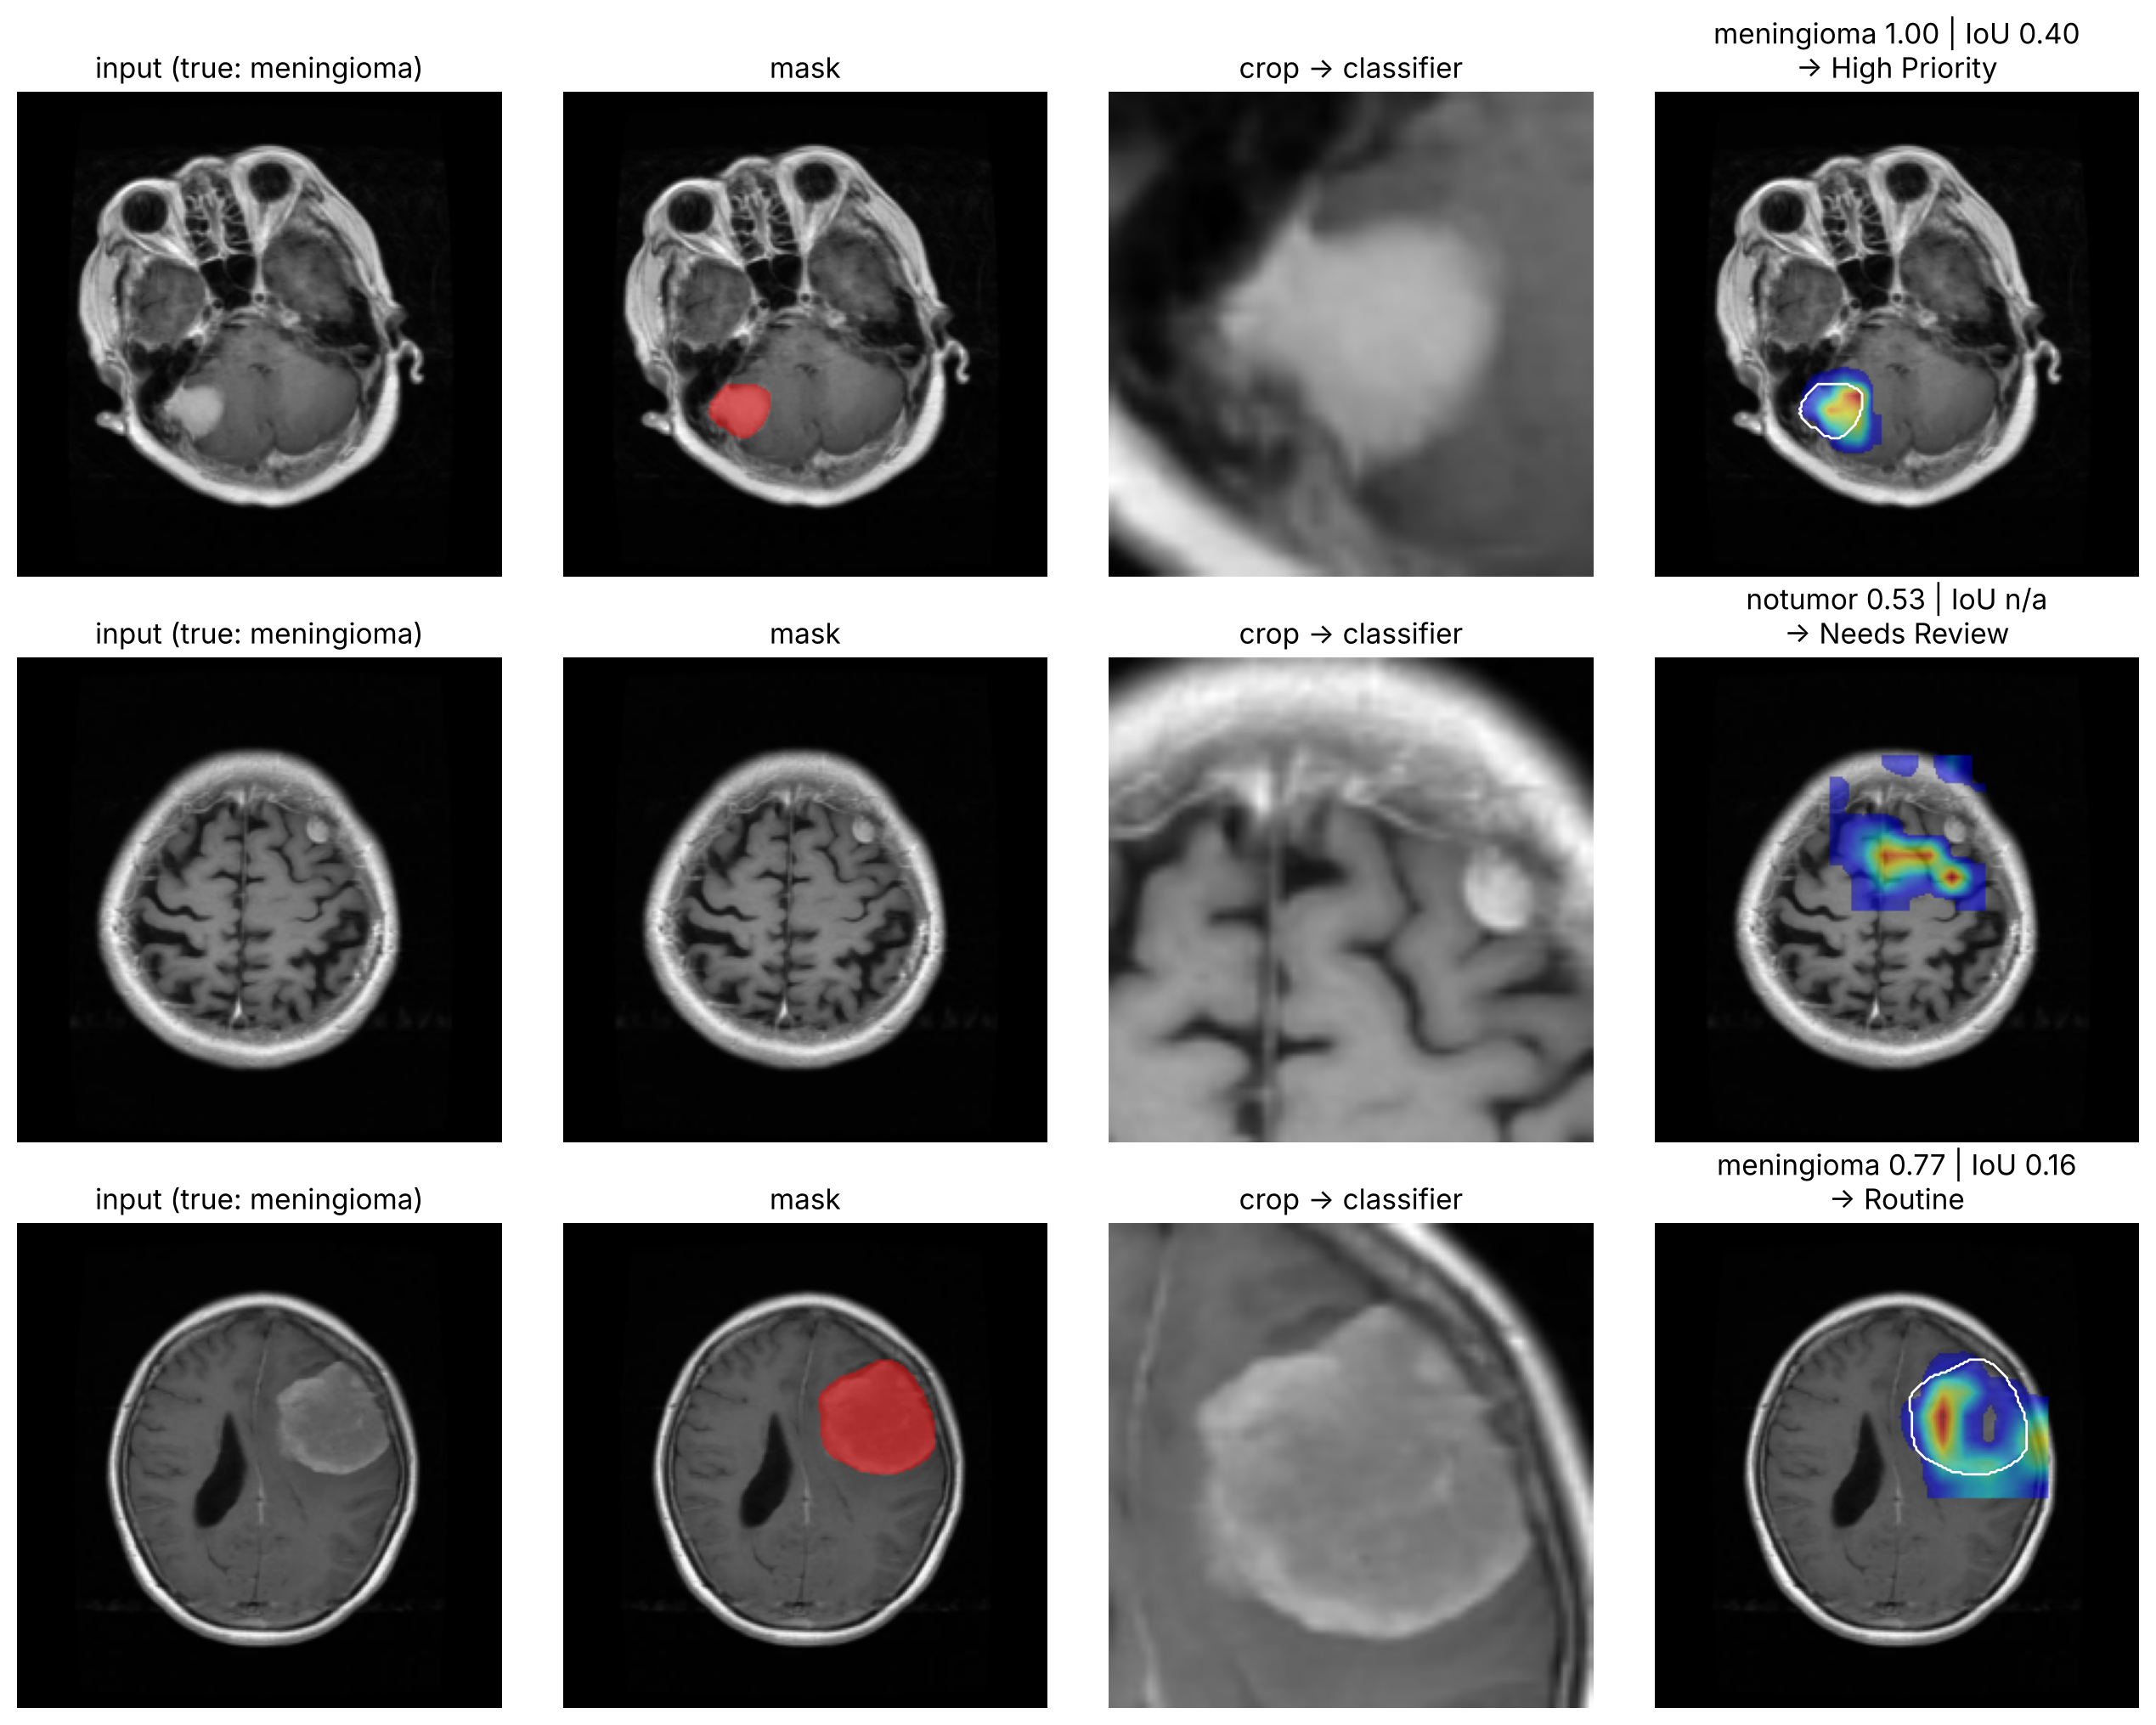

In [5]:
from brain_mri_data import BrainMRIDataset
dev_ds = BrainMRIDataset('dev', root=DATA_ROOT)
picks = [dev.index[dev.tier == t][0] for t in tt.TIERS if (dev.tier == t).any()]
fig, axes = plt.subplots(len(picks), 4, figsize=(13, 3.4 * len(picks)), squeeze=False)
for row, i in zip(axes, picks):
    tt.plot_case(pipe.run_one(dev_ds[i], idx=i), row)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f'examples_{MASK_SOURCE}.png'), dpi=120); plt.show()

## 5. Diagnostic cases: confident mistakes
Wrong predictions with confidence > 0.8. Did the trust check (IoU) catch them?

,path,true,pred,confidence,iou,tier
35,braintumormri_figshare/brainTumorDataPublic_1-...,meningioma,notumor,0.809,NaN,Routine
53,braintumormri_figshare/brainTumorDataPublic_1-...,meningioma,pituitary,0.855,0.004,Needs Review
54,braintumormri_figshare/brainTumorDataPublic_1-...,meningioma,pituitary,0.982,0.000,Needs Review
72,braintumormri_figshare/brainTumorDataPublic_1-...,meningioma,notumor,0.999,NaN,Routine
87,braintumormri_figshare/brainTumorDataPublic_1-...,meningioma,glioma,0.998,0.002,Needs Review
106,braintumormri_figshare/brainTumorDataPublic_1-...,glioma,pituitary,0.947,0.090,Routine
108,braintumormri_figshare/brainTumorDataPublic_1-...,glioma,notumor,0.863,NaN,Routine
186,braintumormri_figshare/brainTumorDataPublic_15...,glioma,pituitary,0.921,0.000,Needs Review
187,braintumormri_figshare/brainTumorDataPublic_15...,glioma,pituitary,0.921,0.174,Routine
199,braintumormri_figshare/brainTumorDataPublic_15...,glioma,pituitary,0.968,0.001,Needs Review


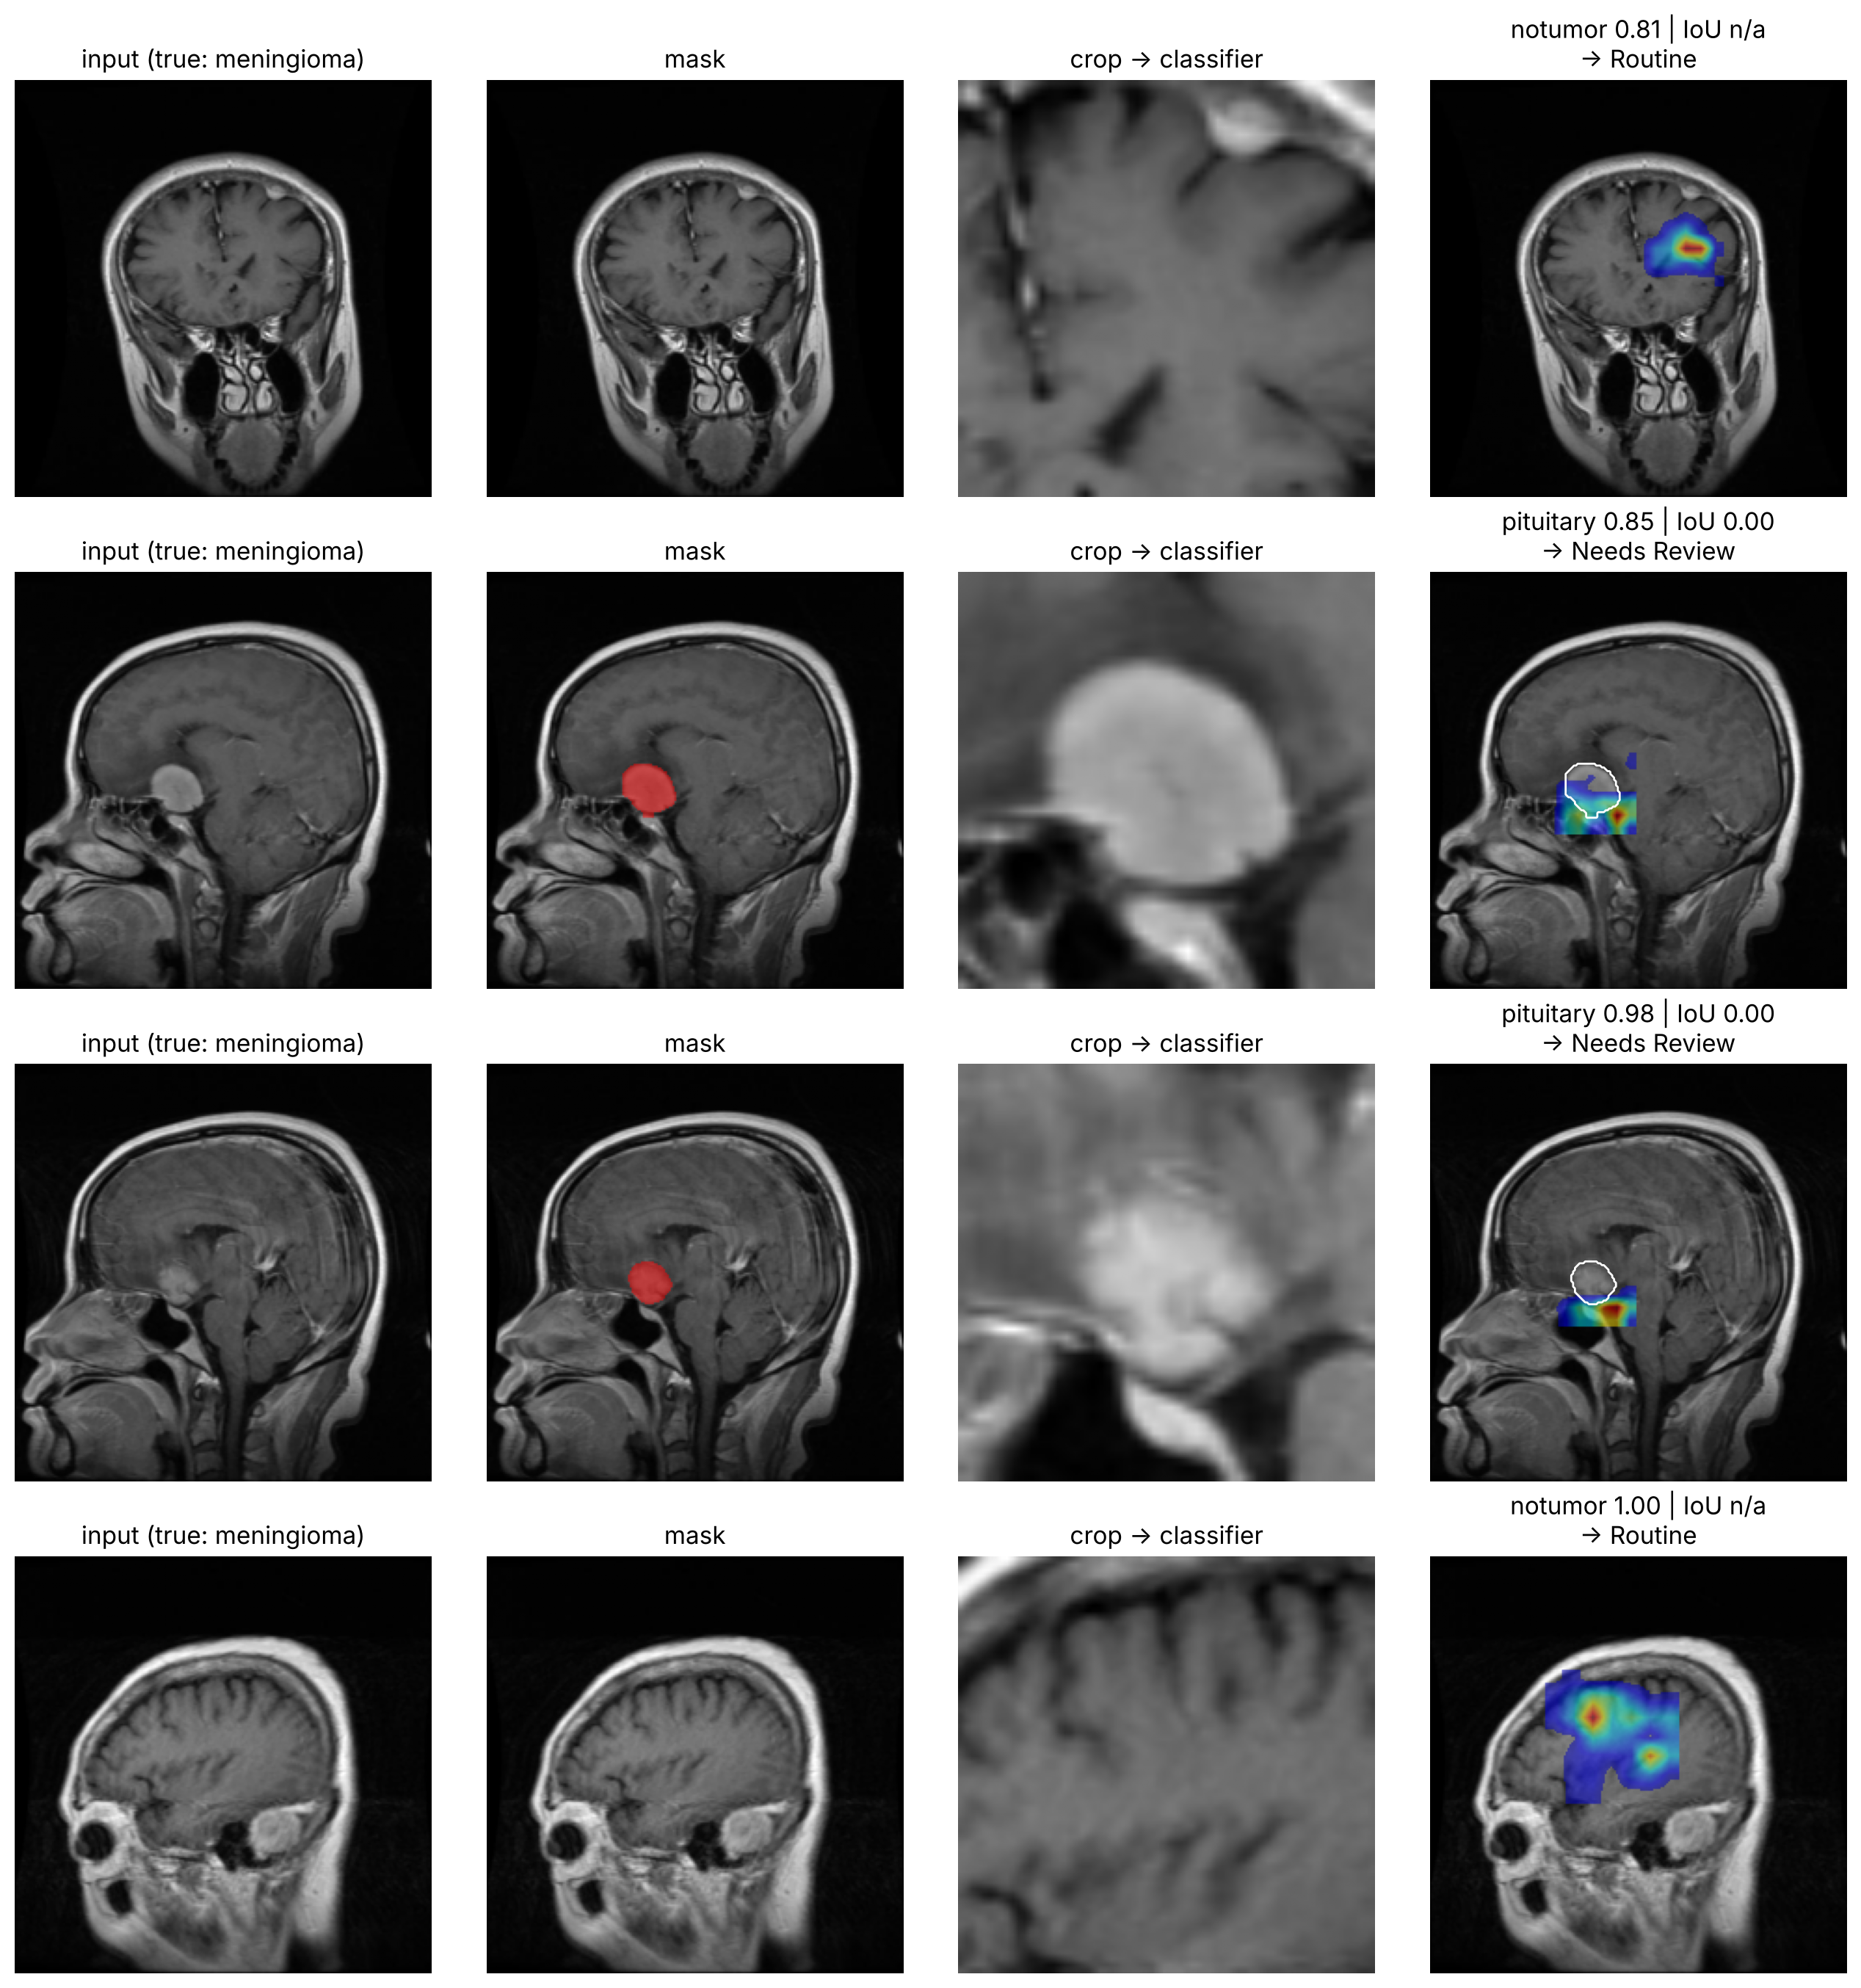

In [6]:
bad = dev[(dev.true != dev.pred) & (dev.confidence > 0.8)]
display(bad[['path', 'true', 'pred', 'confidence', 'iou', 'tier']].round(3))
show = list(bad.index[:4])
if show:
    fig, axes = plt.subplots(len(show), 4, figsize=(13, 3.4 * len(show)), squeeze=False)
    for row, i in zip(axes, show):
        tt.plot_case(pipe.run_one(dev_ds[i], idx=i), row)
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, f'confident_errors_{MASK_SOURCE}.png'), dpi=120); plt.show()

## 6. Ground-truth vs U-Net masks
When `MASK_SOURCE = 'unet'`, `iou` uses the U-Net mask and `iou_vs_gt` uses the true mask. A big gap means mask errors, not model errors, are sending cases to review.

In [7]:
tumor = dev[dev.pred != 'notumor']
print(f"mean IoU (pipeline mask): {tumor.iou.mean():.3f} | mean IoU vs true mask: {tumor.iou_vs_gt.mean():.3f}")
moved = (tumor.iou < 0.30) & (tumor.iou_vs_gt >= 0.30)
print(f"cases sent to review only because of the mask: {int(moved.sum())} of {len(tumor)}")

mean IoU (pipeline mask): 0.155 | mean IoU vs true mask: 0.146
cases sent to review only because of the mask: 13 of 474


## 7. Final test run (once)

In [8]:
if RUN_TEST:
    test = pipe.run_split('test', DATA_ROOT)
    test.to_csv(os.path.join(OUT_DIR, f'test_results_{MASK_SOURCE}.csv'), index=False)
    t_tiers, t_by_class, t_iou, t_key = tt.summarize(test)
    display(t_tiers); display(t_by_class); display(t_iou); display(tt.confusion(test)); display(pd.Series(t_key))
else:
    print('Test set not used (RUN_TEST = False).')

Test set not used (RUN_TEST = False).
